# Lecture 19 notebook: statistics of the book

This notebook replays Lecture 19 on Bybit's BTCUSDT perpetual. Every figure and number of the lecture comes from a script in `scripts/`, next to
this notebook; each runs in a fresh process, so that memory is freed after every step.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings | |
| 1 | The book as a state: the key chart | §1 |
| 2 | The statistics on invented books | §2 |
| 3 | On our 45 days: imbalance, gaming, microprice, queues, markouts, verdicts, the book's clock | §3 |
| 4 | 10 October | §4 |
| 5 | A test of your own: imbalance through the day | §5.2 |

**Before you start.** The notebook uses the Parquet tables of Lecture 18 (environment variable `BYBIT_ROOT`, default `data/bybit` at the top of the
repository; Lecture 18's notebook, §2, shows how to download and convert them). Two kinds of runs are offered:

* **The short check (default).** Every measure is rerun on one day, `CHECK_DAY`, and compared with the lecture's values for that day; the 45-day
  figures are redrawn from the small results shipped in `results/`, and match the lecture's exactly. It needs the Parquet tables of `CHECK_DAY`
  only and takes about six minutes, most of it for the two passes that follow every order in the book's queues (§3, §4).
* **Everything.** With `RUN_ALL = True`, every measure is recomputed on every day in the data folder, the tests are rerun, and the figures are
  drawn from the new results. On the 45 days of the lecture (20 September – 3 November 2025) this takes about three and a half hours, and §4 also needs
  Binance's trades for the same days (`BINANCE_ROOT`, default `data/binance`; §4 shows how to download them).

Results go to `BYBIT_ROOT/interim/l19` (or `L19_OUT`); figures are saved in `figures/` as `nb_*`, so the lecture's own figures are never
overwritten.

## 0. Settings

In [1]:
import json, os, subprocess, sys, time, urllib.request
from pathlib import Path
import numpy as np, polars as pl, psutil
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS)]
import l19 as L
CHECK_DAY = "2025-10-01"                                                   # the day on which every measure is rerun
RUN_ALL = False                                                            # True: recompute everything on every day (about 3.5 hours)

pl.Config.set_tbl_rows(30); pl.Config.set_fmt_str_lengths(80); pl.Config.set_tbl_width_chars(200)
print("data folder:", L.ROOT, "| results:", L.OUT)
print("days with a book:", len(L.days()), (L.days()[0], L.days()[-1]) if L.days() else "")
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB")


def run(script, *args, show=False):
    """Run a script of scripts/ in a fresh process; figures to figures/ as nb_*, results to L.OUT."""
    t0 = time.time()
    env = {**os.environ, "BYBIT_ROOT": str(L.ROOT), "L19_OUT": str(L.OUT), "L19_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, "-I", str(SCRIPTS / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def shipped(name):
    """A result as shipped with the lecture (results/), for comparison with the rerun."""
    return json.loads((L.RESULTS / name).read_text(encoding="utf-8"))


def compare(rows):
    """rows: (measure, lecture's value, this run's value)."""
    return pl.DataFrame([(m, float(a), float(b)) for m, a, b in rows], schema=["measure", "lecture", "this run"], orient="row")


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)


def auc(score, up):
    """Probability that a random up move had a higher score than a random down move (ties count half)."""
    r = pl.Series(score).rank("average").to_numpy(); up = np.asarray(up, bool); n1 = up.sum(); n0 = len(up) - n1
    return (r[up].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

data folder: D:\trading-data\bybit | results: D:\trading-data\bybit\interim\l19_nbtest
days with a book: 45 ('2025-09-20', '2025-11-03')
free memory: 1.4 GB of 16.9 GB


## 1. The book as a state

`l19_state.py` replays the book of a day from its Parquet table and keeps, after every update, the best bid and ask and the sizes at the best and
in the best 5 levels of each side: one row per update, about 860,000 a day. Figure 19_01 is the plan of Part IV; 19_02 the key chart, the
share of next mid moves that were up by the imbalance at the best just before. For `CHECK_DAY` the counts behind it are compared with the
lecture's, band by band.

In [2]:
run("l19_state.py", CHECK_DAY)
run("l19_key_bins.py", CHECK_DAY)
mine, lec = json.loads((L.OUT / "check_l19_key_bins.json").read_text())[CHECK_DAY], shipped("l19_key_bins.json")[CHECK_DAY]
b = sorted(lec, key=int)
display(compare([("updates with a one-tick spread", sum(lec[k][2] for k in b), sum(mine[k][2] for k in b))] +
                [(f"band {k}: share of next moves up", lec[k][1] / lec[k][2], mine[k][1] / mine[k][2]) for k in b[::4]]))

l19_state.py 2025-10-01: 54 s


l19_key_bins.py 2025-10-01: 1 s


measure,lecture,this run
str,f64,f64
"""updates with a one-tick spread""",861943.0,861943.0
"""band 0: share of next moves up""",0.166021,0.166021
"""band 4: share of next moves up""",0.338938,0.338938
"""band 8: share of next moves up""",0.436632,0.436632
"""band 12: share of next moves up""",0.556796,0.556796
"""band 16: share of next moves up""",0.681935,0.681935


l19_s1_charts.py : 5 s


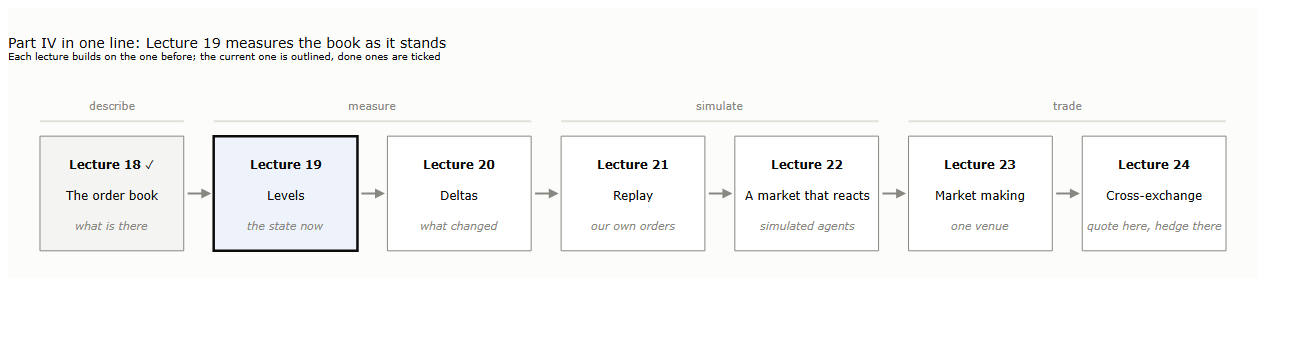

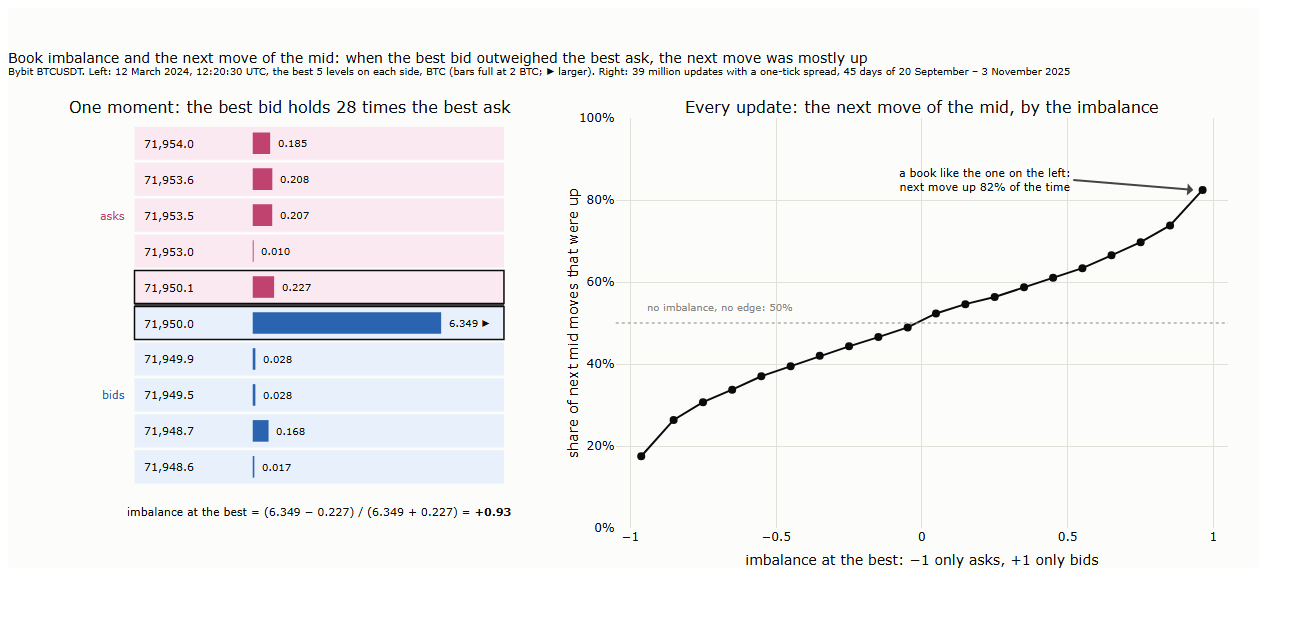

In [3]:
if RUN_ALL:
    for d in L.days():
        if not (L.STATE / f"{d}.parquet").exists(): run("l19_state.py", d)    # about half a minute a day
    run("l19_key_bins.py")
run("l19_s1_charts.py")
pictures("19_01_part_iv", "19_02_imbalance_key")

## 2. The statistics on invented books

The cards of §2 use invented books, so that what each statistic is meant to capture is clear before it meets the data: imbalance (19_03), the
microprice (19_04), a spoof (19_05), the race to a stale quote (19_06), the shape of the book (19_07), a queue (19_08) and a markout (19_09).

l19_s2_cards.py : 14 s


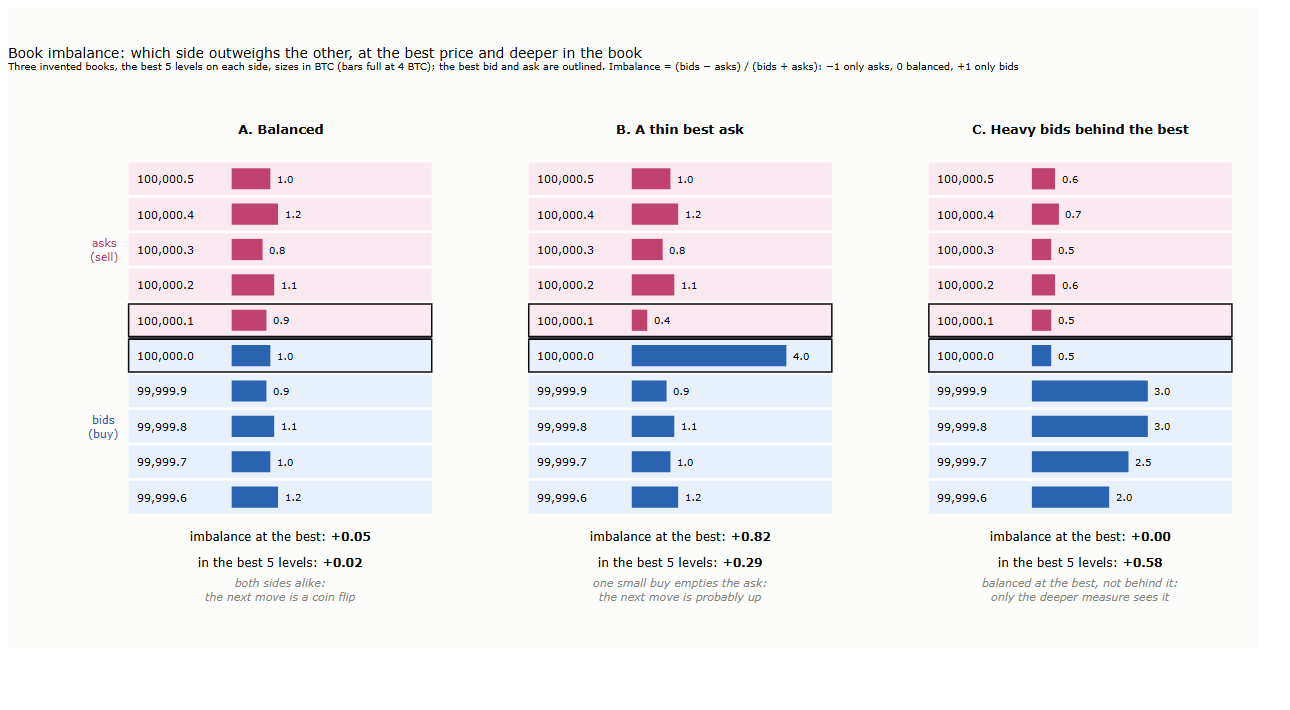

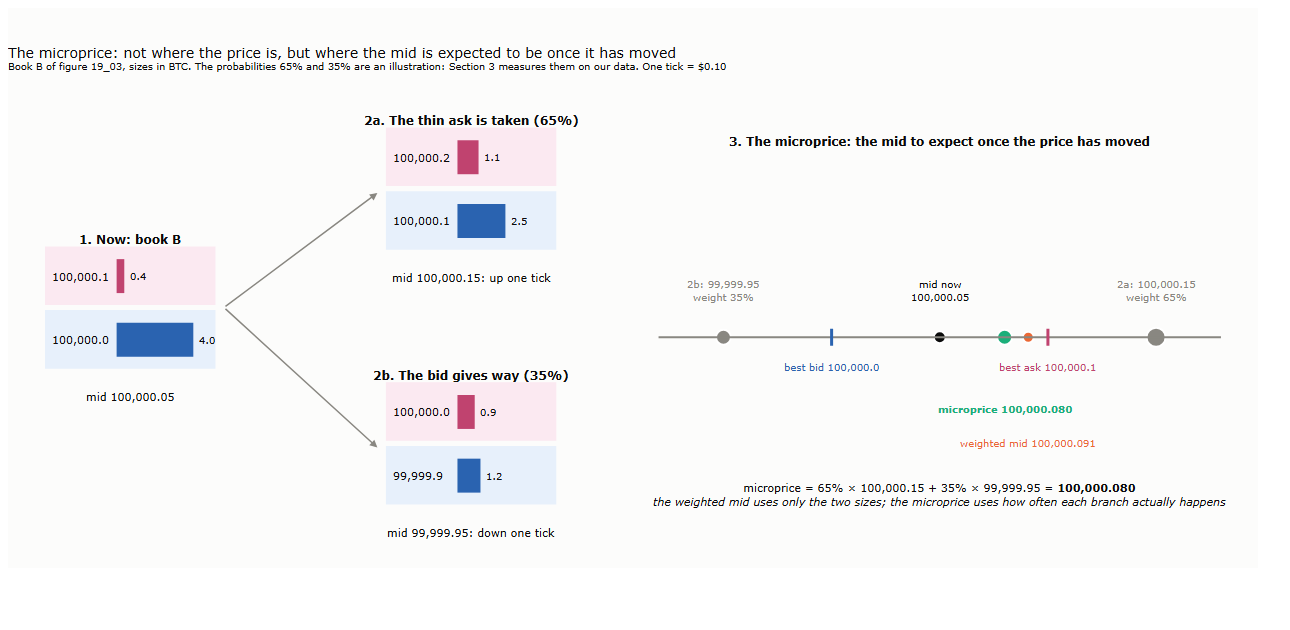

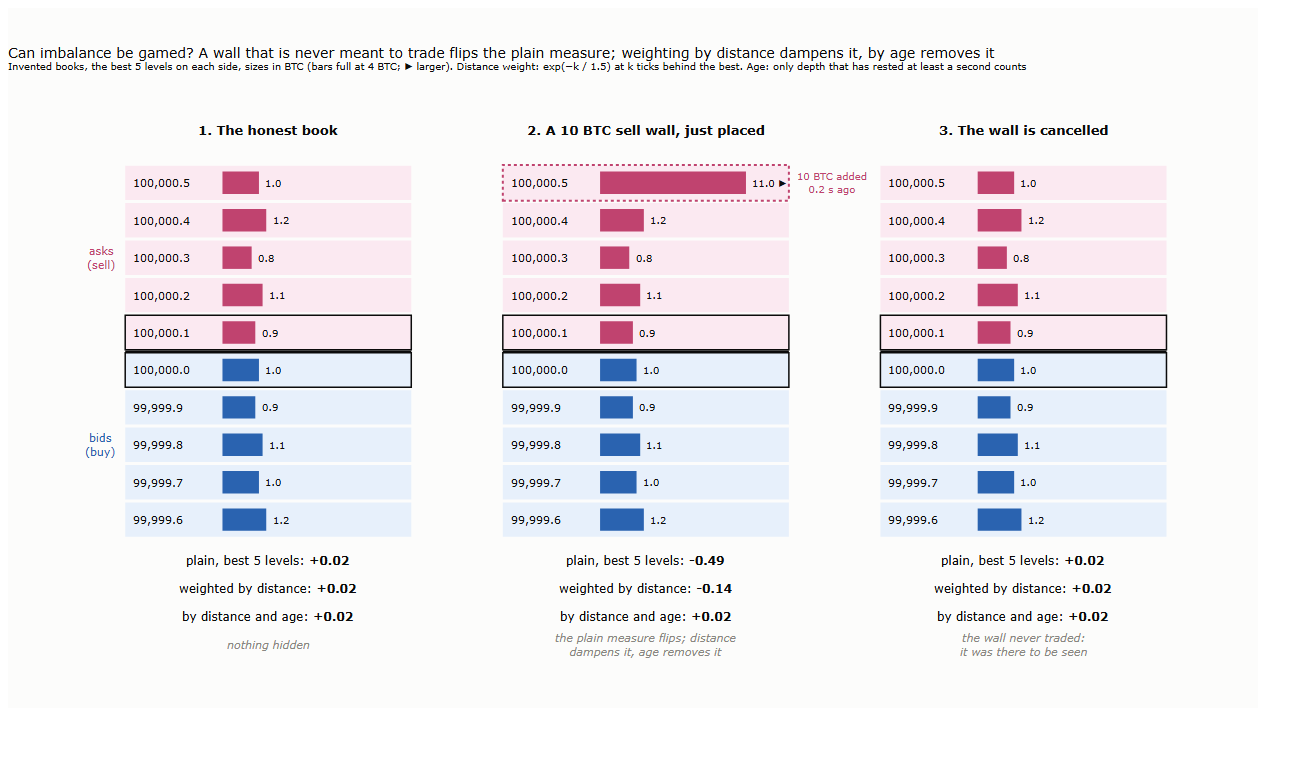

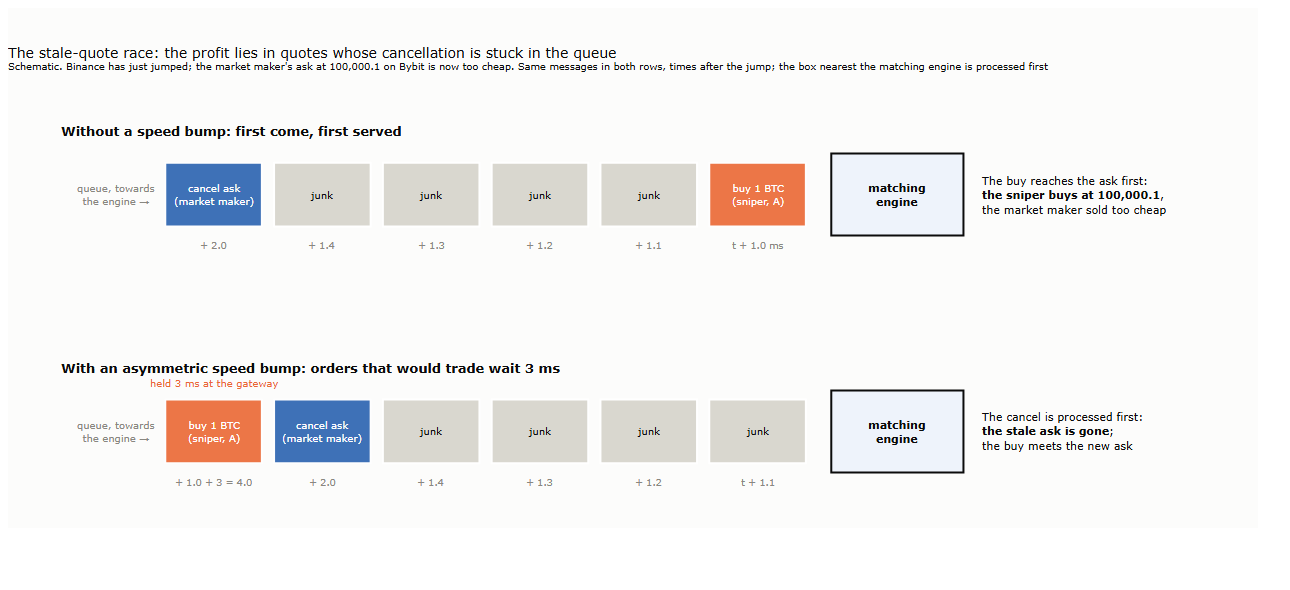

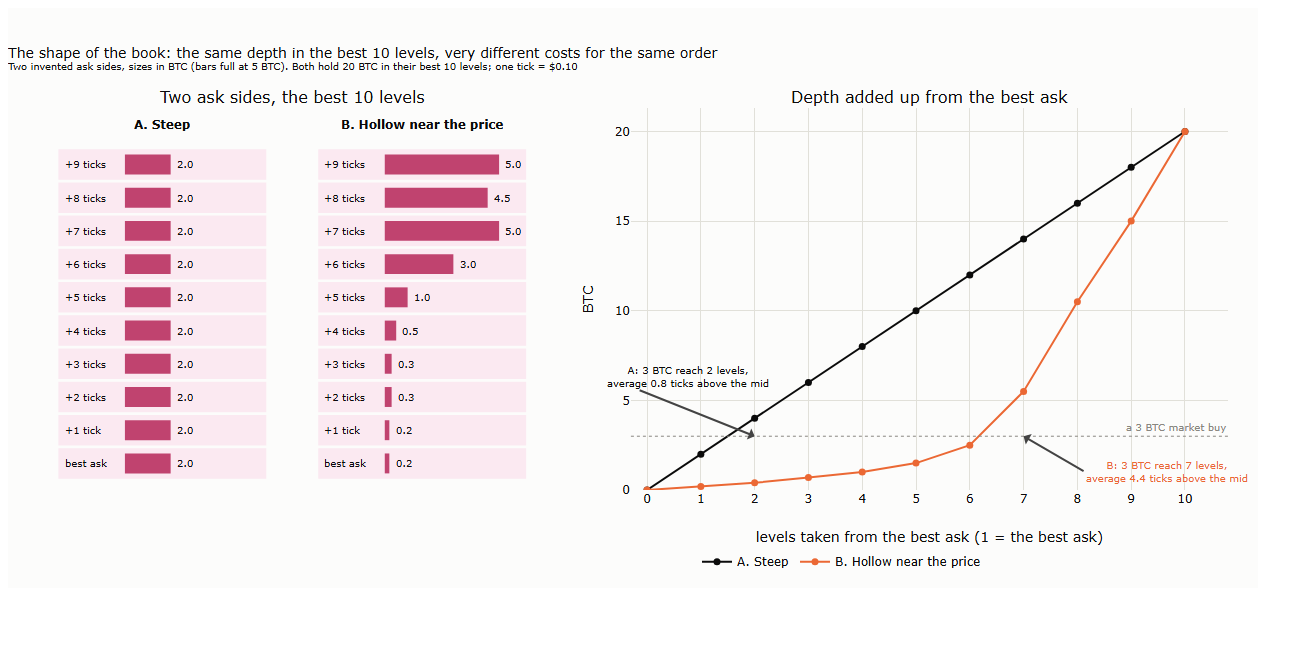

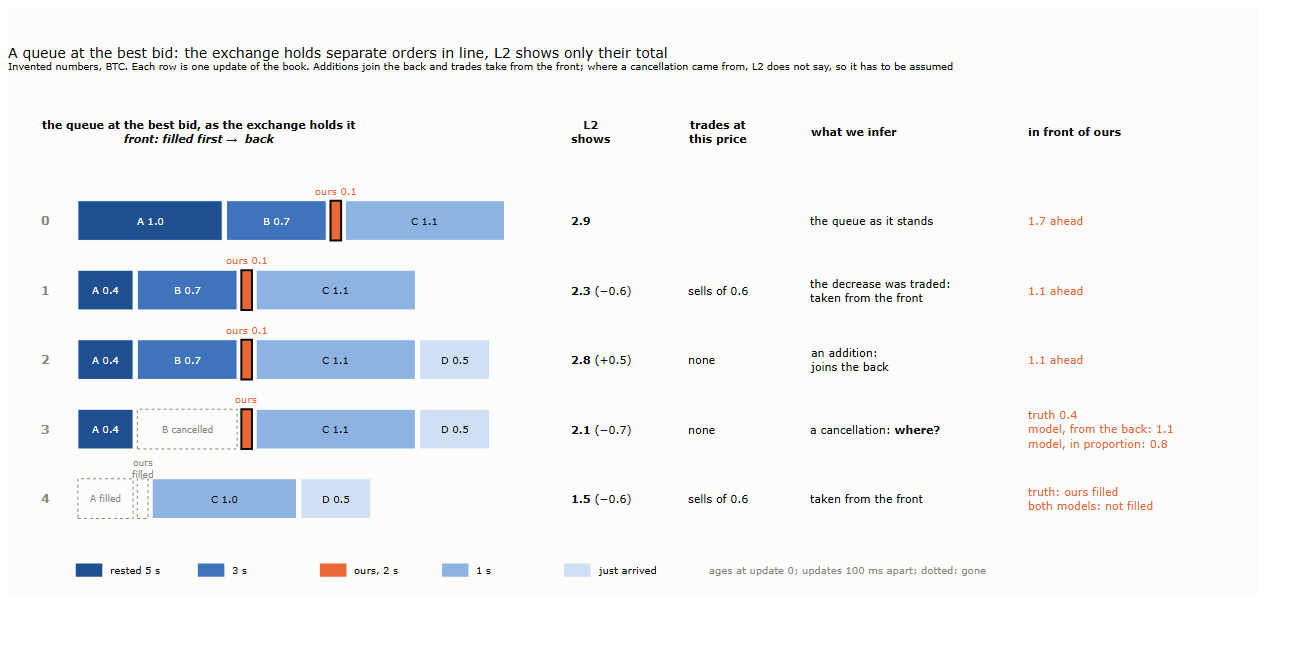

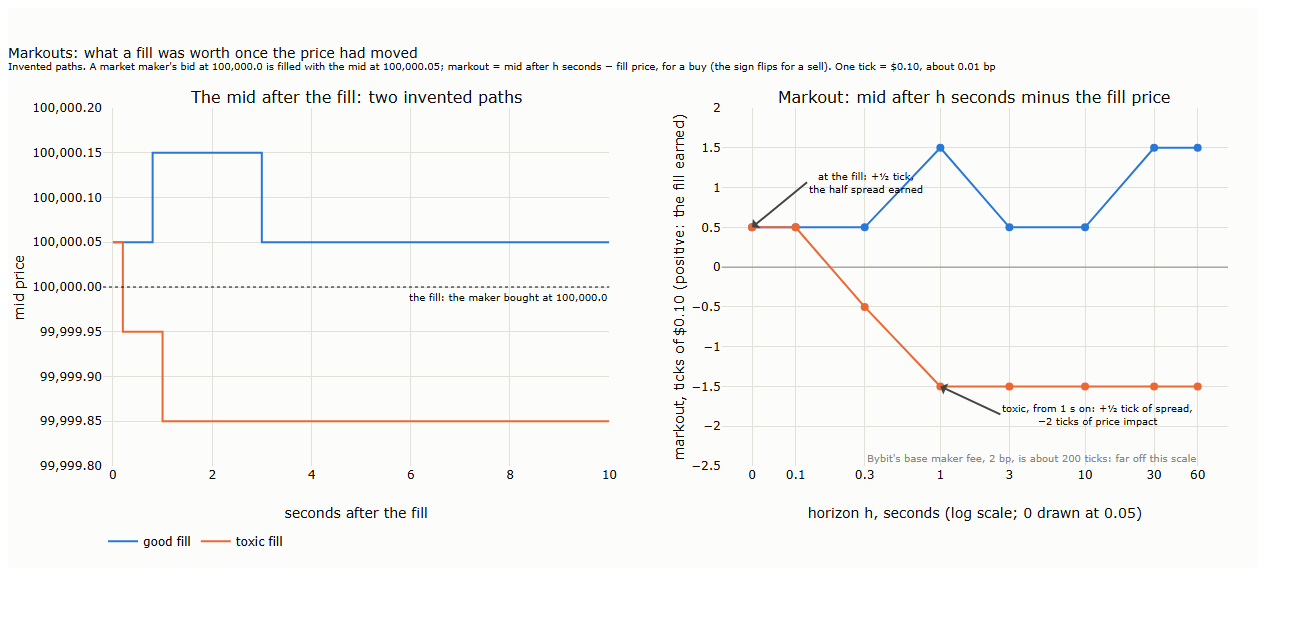

In [4]:
run("l19_s2_cards.py")
pictures("19_03_imbalance_card", "19_04_microprice_card", "19_05_spoofing_card", "19_06_stale_quote_race", "19_07_shape_card", "19_08_queue_card",
         "19_09_markout_card")

## 3. On our 45 days

Three passes per day. `l19_s3_day.py` draws the samples of §3.1 (one per interval between two changes of the mid, at a random update inside it, as
in Gould and Bonart, 2015) and the markouts of every taker order (§3.5); `l19_s3_dt.py` times each sample to the next change of the mid.
`l19_book2.py` follows every level of the book as a first-in, first-out queue (§2.4): the weighted and age-filtered imbalance (§3.2), the spoof
candidates, depth each minute, the queues at the best and the refilling chains (§3.4). It is the slow one, about a minute and a half a day.

In [5]:
run("l19_s3_day.py", CHECK_DAY); run("l19_s3_dt.py"); run("l19_book2.py", CHECK_DAY)
S = pl.read_parquet(L.S3 / f"samples_{CHECK_DAY}.parquet")
lec1, lec2 = shipped("l19_s3_stats.json"), shipped("l19_s3_stats2.json")
day = next(r for r in lec1["daily"] if r["day"] == CHECK_DAY)
J = json.loads((L.S3 / f"b2_{CHECK_DAY}.json").read_text()); q = {k: J["queues"]["1"][k] + J["queues"]["-1"][k] for k in ("added", "traded", "cancelled")}
q0, ice0 = lec2["H10_daily"][CHECK_DAY], lec2["icebergs"][CHECK_DAY]
compare([("samples", day["n"], S.height),
         ("AUC of the imbalance at the best", day["auc"], auc(S["I1"], S["up"])),
         ("BTC added to the best queues", q0["added"], q["added"]), ("BTC traded at the best", q0["traded"], q["traded"]),
         ("BTC cancelled at the best", q0["cancelled"], q["cancelled"]),
         ("refills within 1 s of being traded away", ice0["refills"], J["ice_refills"]), ("refilling chains of 3 or more", ice0["chains3"], J["ice_chains"])])

l19_s3_day.py 2025-10-01: 1 s


l19_s3_dt.py : 1 s


l19_book2.py 2025-10-01: 99 s


measure,lecture,this run
str,f64,f64
"""samples""",42226.0,42226.0
"""AUC of the imbalance at the best""",0.896941,0.896943
"""BTC added to the best queues""",192785.564,192785.564
"""BTC traded at the best""",38221.541,38221.541
"""BTC cancelled at the best""",517213.233,517213.233
"""refills within 1 s of being traded away""",5635.0,5635.0
"""refilling chains of 3 or more""",38.0,38.0


The lecture's AUC is computed from histograms of 4,000 bins, so that resampling days only adds histograms; the exact value here may differ in the
fourth decimal. The spoof candidates of the day, by distance from the best, against the lecture's:

In [6]:
run("l19_cand_summary.py", CHECK_DAY)
mine, lec = json.loads((L.OUT / "check_l19_cand_offsets.json").read_text())[CHECK_DAY], shipped("l19_cand_offsets.json")[CHECK_DAY]
compare([(f"{k} ticks behind: candidates", lec[k][2], mine.get(k, [0, 0, 0])[2]) for k in sorted(lec, key=int)])

l19_cand_summary.py 2025-10-01: 1 s


measure,lecture,this run
str,f64,f64
"""1 ticks behind: candidates""",1191.0,1191.0
"""2 ticks behind: candidates""",459.0,459.0
"""3 ticks behind: candidates""",566.0,566.0
"""4 ticks behind: candidates""",310.0,310.0
"""5 ticks behind: candidates""",286.0,286.0
"""6 ticks behind: candidates""",260.0,260.0
"""7 ticks behind: candidates""",248.0,248.0
"""8 ticks behind: candidates""",257.0,257.0
"""9 ticks behind: candidates""",258.0,258.0


**The tests and the figures.** With `RUN_ALL`, the three passes run on every day, then `l19_s3_stats.py` (H1–H5, H8, H12, H13) and
`l19_s3_stats2.py` (H6, H7, H9–H11, the icebergs, and the Benjamini-Hochberg correction over all 15). Otherwise the figures 19_10 to 19_14 are
drawn from the shipped results.

l19_s3_charts.py : 9 s


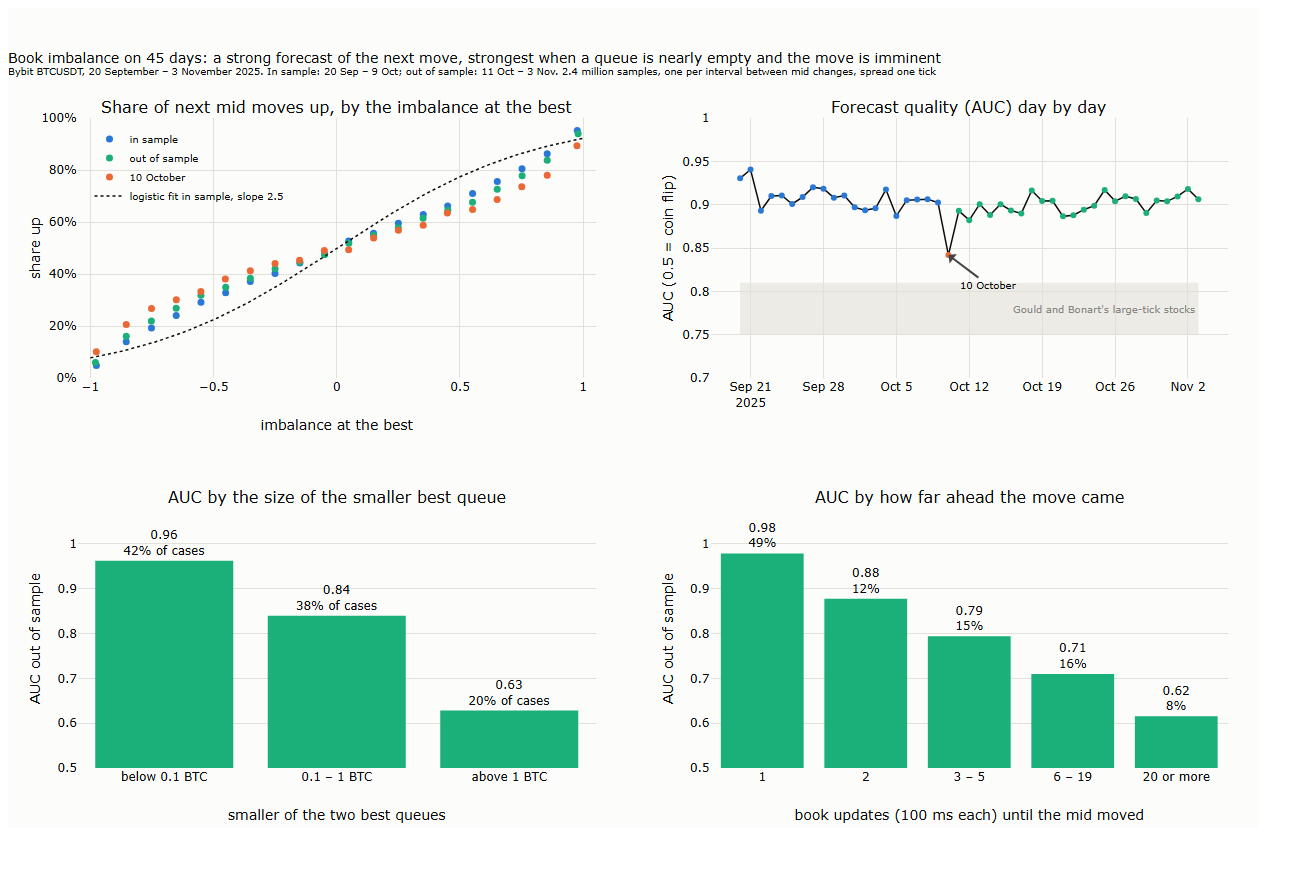

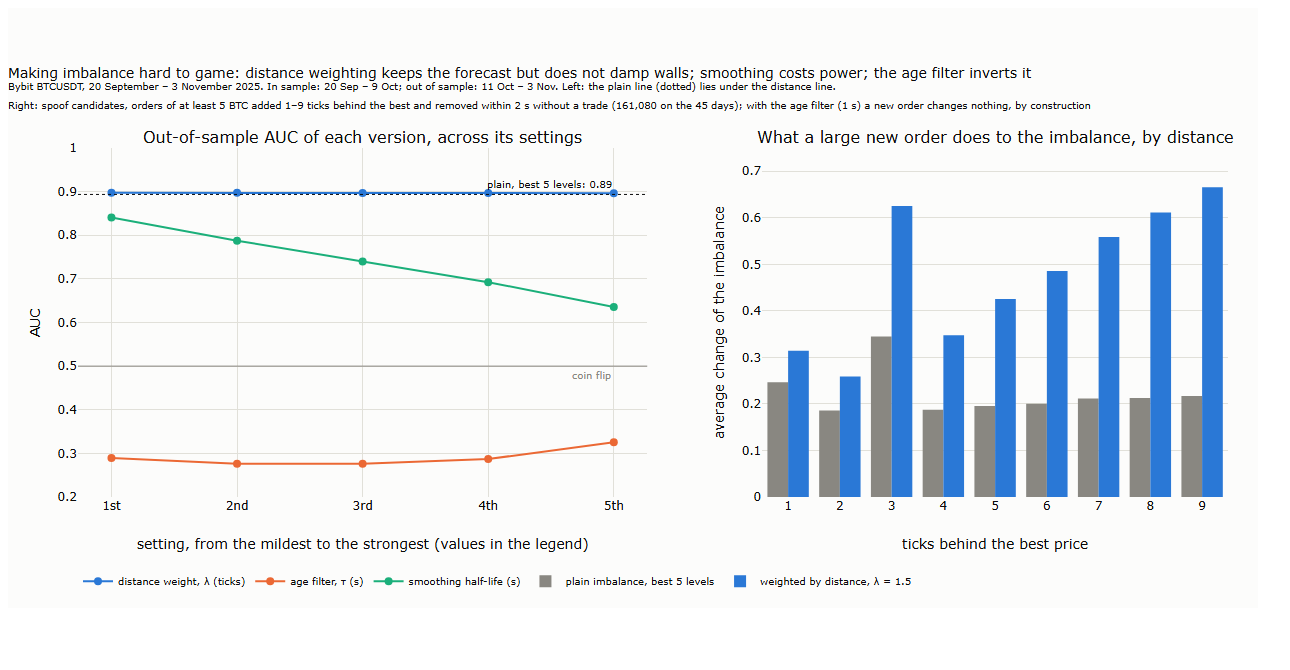

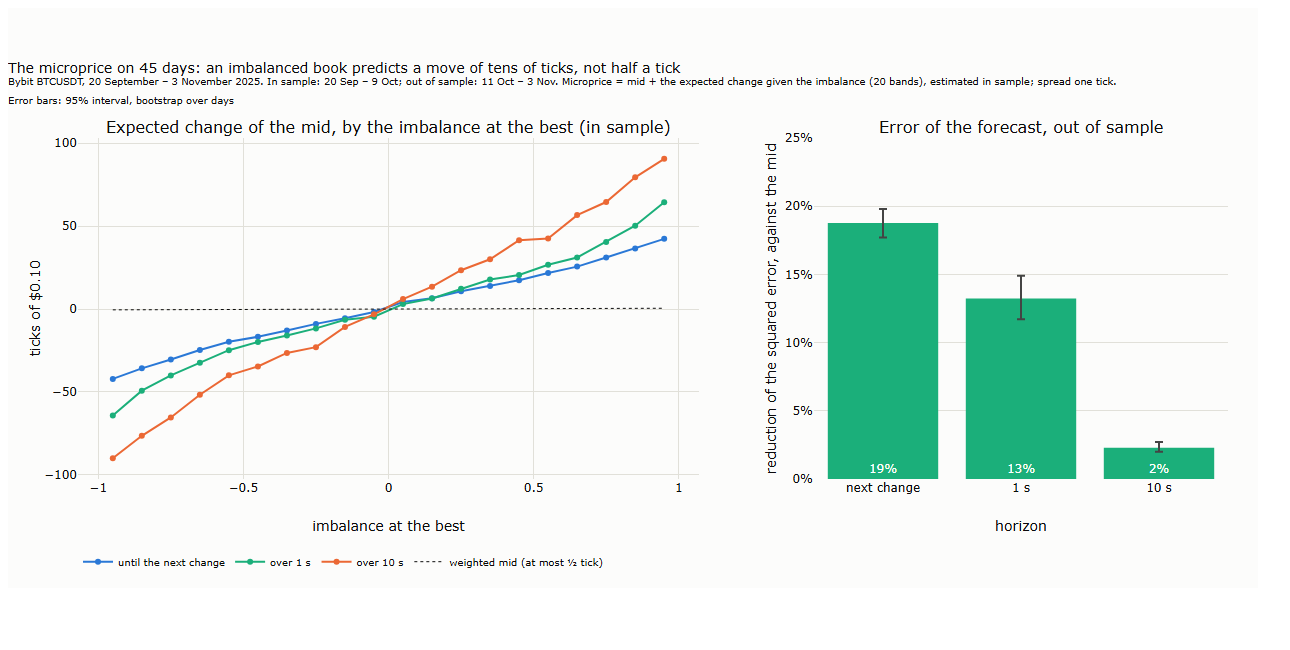

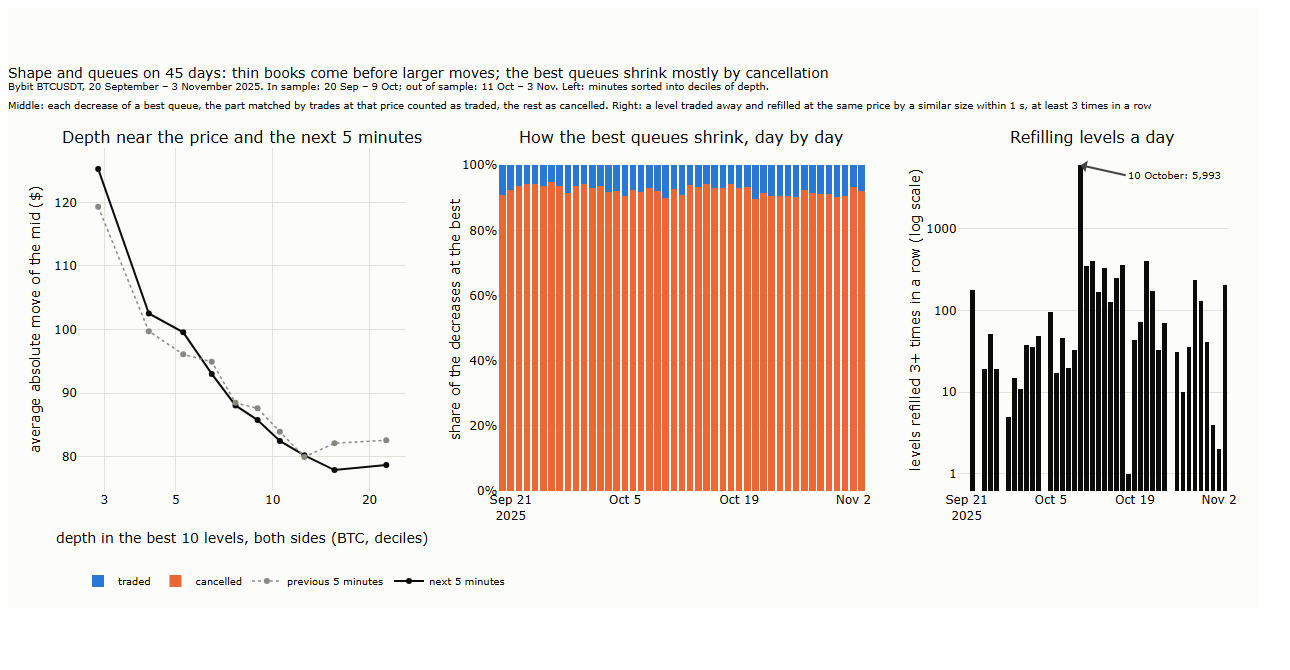

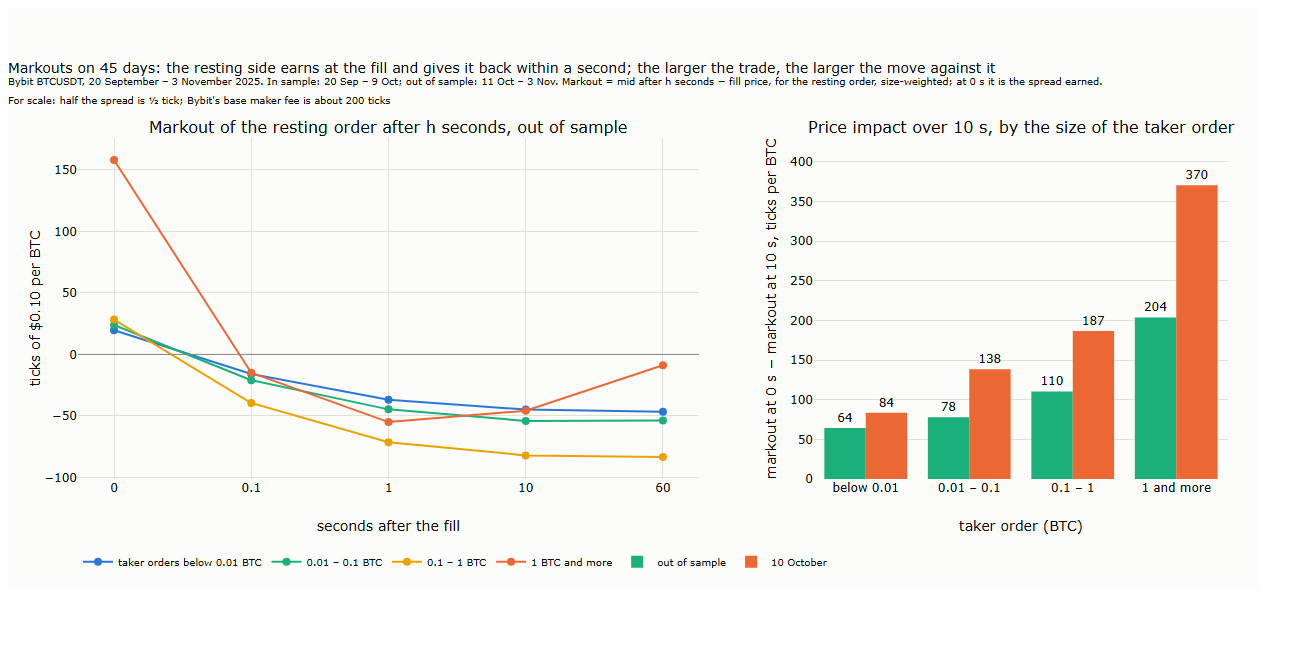

In [7]:
if RUN_ALL:
    for d in L.days():
        run("l19_s3_day.py", d)                                                # skips days already done
        if not (L.S3 / f"b2_{d}.json").exists(): run("l19_book2.py", d)
    run("l19_s3_dt.py"); run("l19_cand_summary.py"); run("l19_s3_stats.py"); run("l19_s3_stats2.py")
run("l19_s3_charts.py")
pictures("19_10_imbalance_results", "19_11_gaming_results", "19_12_microprice_results", "19_13_shape_queue_results", "19_14_markout_results")

The verdicts of §3.6: each p-value and whether the hypothesis holds after the Benjamini-Hochberg correction at 5%.

In [8]:
R2 = json.loads(L.result_path("l19_s3_stats2.json").read_text())
pl.DataFrame([dict(hypothesis=k, p=v["p"], holds=v["reject_null"]) for k, v in R2["BH"].items()])

hypothesis,p,holds
str,f64,bool
"""H1""",0.0,true
"""H2""",2.8422e-14,true
"""H3""",0.0,true
"""H4""",0.9995,false
"""H5""",0.0,true
"""H6 distance""",0.0,true
"""H6 age""",1.0,false
"""H6 smoothed""",1.0,false
"""H7""",2.8422e-14,true


**§3.7, the book's clock.** `l19_s37_clock.py` tests H19–H23, added after the results above with their hypotheses fixed before computing: pulls,
the spread and depth at the round times of Lecture 13 against control minutes, and whether the orders at :00 and :30 follow the last half hour.
It reads the book state of every day and Lecture 18's pulls (`L18_OUT/pulls`, from Lecture 18's notebook), so it runs only with `RUN_ALL`; figure
19_16 is otherwise drawn from the shipped results.

l19_s37_charts.py : 4 s


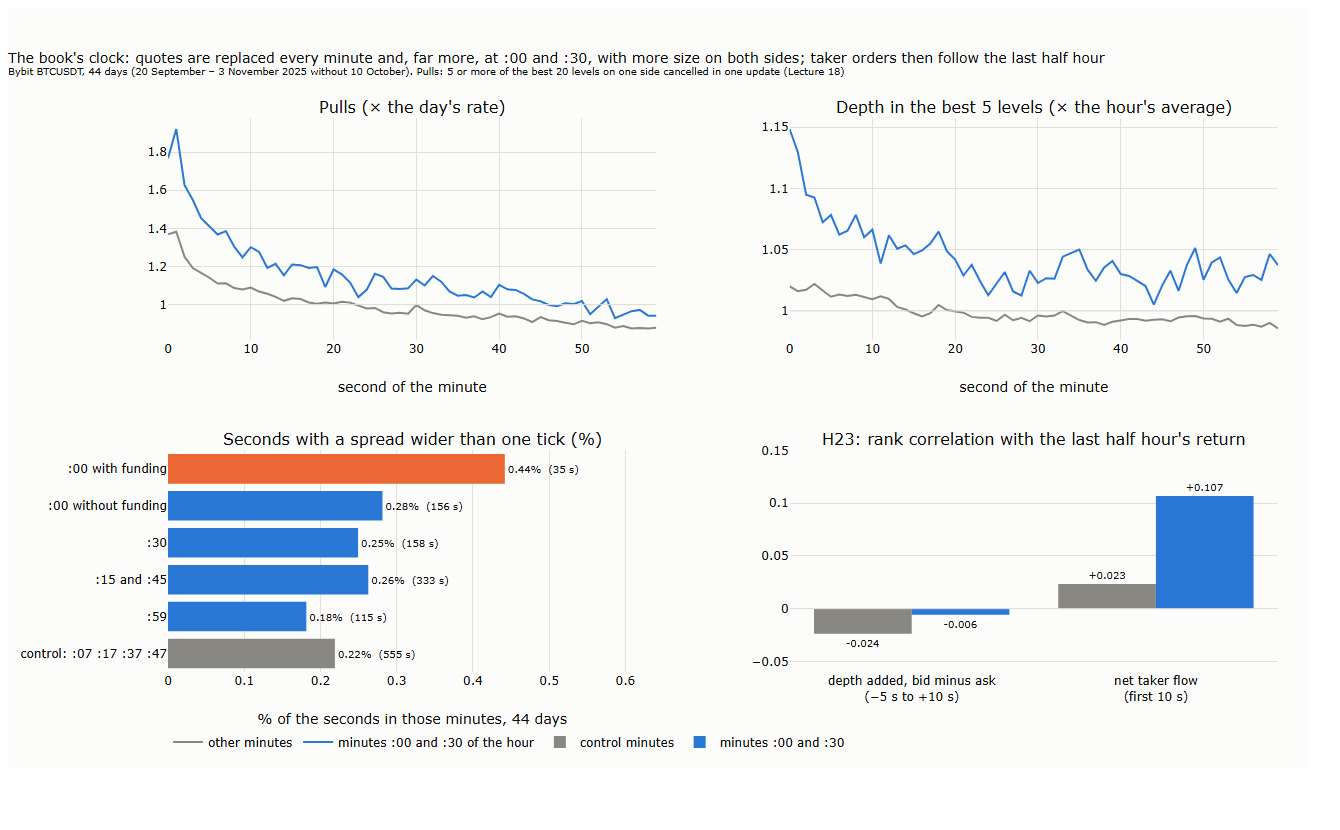

test,mean_difference,p,holds
str,f64,f64,bool
"""H19_spread|other_00""",0.4105,0.0005,true
"""H21_pulls|funding_00""",0.3959,0.0005,true
"""H21_pulls|other_00""",0.1309,0.0005,true
"""H23b""",0.0835,0.0005,true
"""H21_pulls|m30""",0.0523,0.001,true
"""H19_spread|funding_00""",2.1178,0.0115,true
"""H19_spread|m15_45""",0.2309,0.0115,true
"""H22|H19_spread""",1.7072,0.0765,false
"""H19_spread|m30""",0.1351,0.2265,false


In [ ]:
if RUN_ALL: run("l19_s37_clock.py")                                        # one pass over all days, a few minutes
run("l19_s37_charts.py")
pictures("19_16_book_clock")
R37 = json.loads(L.result_path("l19_s37_stats.json").read_text())
pl.DataFrame([dict(test=k, mean_difference=round(v["mean_d"], 4), p=round(v["p"], 4), holds=v["holds"]) for k, v in {**R37["tests"], **R37["H23"]}.items()]).sort("p")

## 4. 10 October

`l19_book3.py` repeats the queue pass and records the time of every refilling chain and Bybit's publish delay, the time between the matching
engine's stamp and the publication of each update (`ts − cts`). On `CHECK_DAY` the chains must equal those of §3, and the daily 99th percentile of
the delay should lie in the range the lecture reports for ordinary days, 8 to 27 milliseconds.

In [9]:
run("l19_book3.py", CHECK_DAY)
lag = pl.read_parquet(L.S3 / f"b3_lag_{CHECK_DAY}.parquet")["lag"]
print(f"publish delay on {CHECK_DAY}: median {lag.median():.0f} ms, 99th percentile {lag.quantile(0.99):.0f} ms (lecture: 99th percentile 8 to 27 ms on ordinary days)")
compare([("refilling chains (as in §3)", shipped("l19_s3_stats2.json")["icebergs"][CHECK_DAY]["chains3"], pl.read_parquet(L.S3 / f"b3_ice_{CHECK_DAY}.parquet").height)])

l19_book3.py 2025-10-01: 117 s
publish delay on 2025-10-01: median 3 ms, 99th percentile 18 ms (lecture: 99th percentile 8 to 27 ms on ordinary days)


measure,lecture,this run
str,f64,f64
"""refilling chains (as in §3)""",38.0,38.0


**Everything.** The test of §4 compares the two hours before the start of the cascade with every two-hour window of the other 44 days, so it needs
all days, and Binance's trades for them. The download (about 0.1–0.4 GB a day, from Binance's public archive) is off by default.

l19_s4_charts.py : 4 s


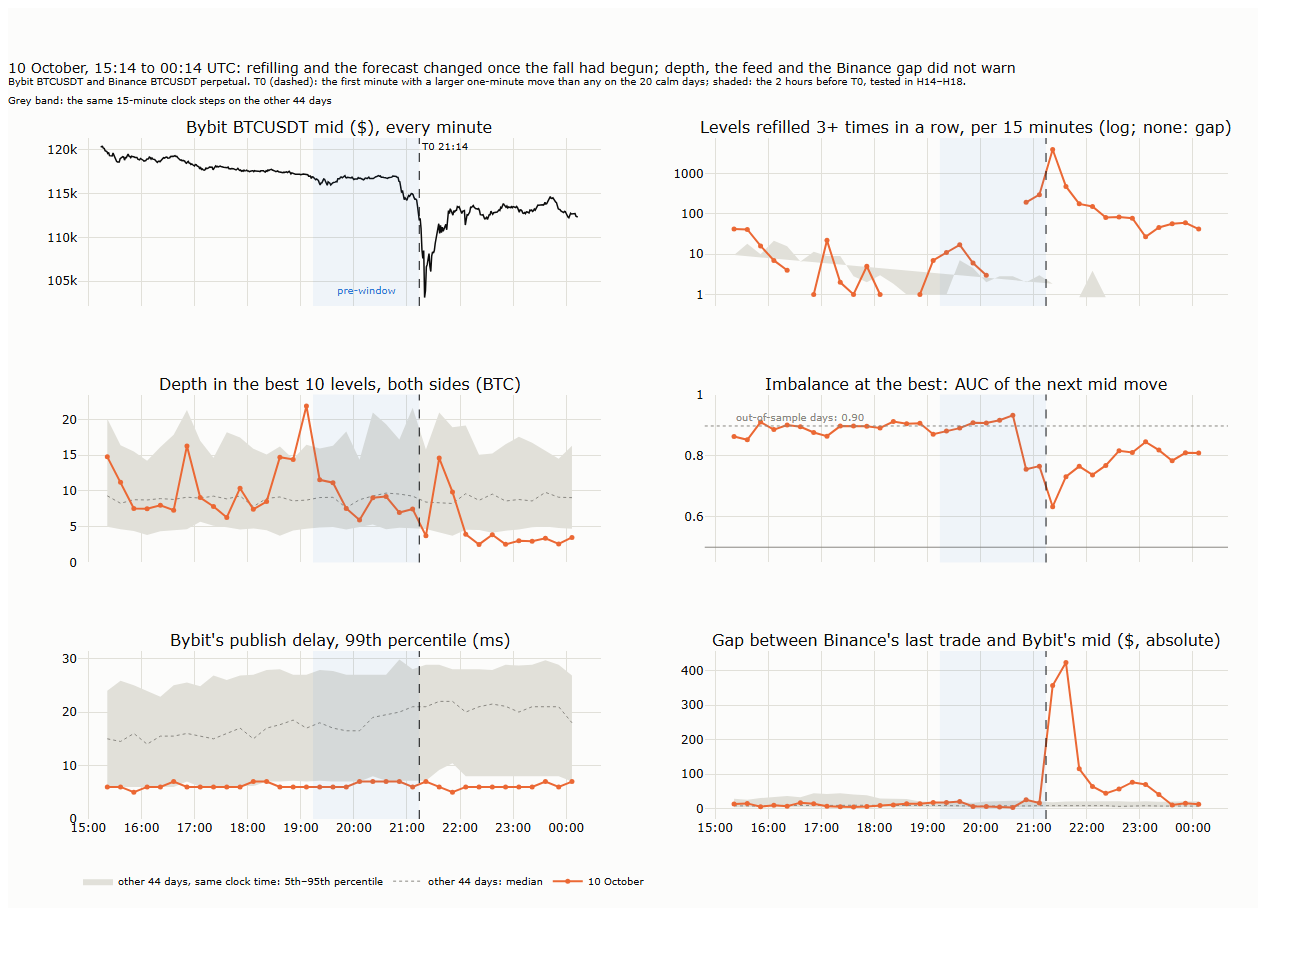

In [10]:
DOWNLOAD_BINANCE = False
if DOWNLOAD_BINANCE:
    L.BN_RAW.mkdir(parents=True, exist_ok=True)
    for d in L.days():
        f = L.BN_RAW / f"BTCUSDT-aggTrades-{d}.zip"
        if not f.exists():
            urllib.request.urlretrieve(f"https://data.binance.vision/data/futures/um/daily/aggTrades/BTCUSDT/BTCUSDT-aggTrades-{d}.zip", f); print(d, "downloaded")
if RUN_ALL:
    for d in L.days():
        if not (L.S3 / f"b3_lag_{d}.parquet").exists(): run("l19_book3.py", d)   # about a minute and a half a day
    run("l19_t0.py", show=True); run("l19_s4_stats.py")
run("l19_s4_charts.py")
pictures("19_15_cascade_evening")

The verdicts of §4: the value on 10 October, its p-value and whether the hypothesis holds after the correction.

In [11]:
R4 = json.loads(L.result_path("l19_s4_stats.json").read_text())
print("T0:", pl.from_epoch(pl.Series([R4["T0"]]), time_unit="ms")[0], "UTC; pre-window:", R4["pre"])
pl.DataFrame([dict(hypothesis=k, p=v["p"], holds=v["reject_null"]) for k, v in R4["BH"].items()])

T0: 2025-10-10 21:14:00 UTC; pre-window: {'chains': 530.0, 'depth': 8.61455, 'lag99': 6.0, 'absgap': 12.656783333331957}


hypothesis,p,holds
str,f64,bool
"""H14""",0.001898,true
"""H15""",0.426945,false
"""H16""",1.0,false
"""H17""",0.0,true
"""H18a""",0.254269,false
"""H18b""",0.0105,true


## 5. A test of your own: imbalance through the day

Does the forecast of the imbalance at the best change with the hour? Lecture 18 found that the book is thinner and dearer between 13:00 and 22:00
UTC. The AUC of `CHECK_DAY`'s samples, hour by hour, with the share of samples whose smaller best queue held less than 0.1 BTC, the mechanics of
§3.1. Change the day (10 October is the obvious one), or group by another quantity of the samples.

In [12]:
S = pl.read_parquet(L.S3 / f"samples_{CHECK_DAY}.parquet").with_columns(pl.from_epoch("ts", time_unit="ms").dt.hour().alias("hour"))
pl.DataFrame([dict(hour=h, samples=g.height, auc=auc(g["I1"], g["up"]), tiny_queue_share=(g["qmin"] < 0.1).mean())
              for (h,), g in sorted(S.group_by("hour"), key=lambda x: x[0])])

hour,samples,auc,tiny_queue_share
i64,i64,f64,f64
0,1144,0.937023,0.281469
1,1181,0.918879,0.248095
2,782,0.914929,0.202046
3,1060,0.900096,0.228302
4,1416,0.905258,0.211158
5,1158,0.897724,0.273748
6,1444,0.903825,0.243075
7,1232,0.90336,0.262987
8,4281,0.871706,0.20953
